# Notebook 6: Sentiment Analysis of Consumer Financial Complaints

## Objective

This notebook applies pretrained transformer models to estimate the sentiment expressed in consumer complaint narratives.

The analysis will:

- compare suitable pretrained sentiment models;
- evaluate prediction distributions and confidence scores;
- measure agreement and disagreement between models;
- inspect a small number of predictions qualitatively;
- account for narratives exceeding transformer token limits;
- select one model for the final sentiment analysis;
- measure real sentiment volumes using the full narrative dataset;
- compare products fairly using the equal-product corpus.



## Dataset Roles

Two prepared datasets from Notebook 5 are used:

### 1. Full narrative dataset

- File: `full_narratives_prepared.csv`
- Size: 272,466 complaint narratives
- Purpose: estimate real complaint volumes and overall sentiment patterns.

### 2. Equal-product NLP corpus

- File: `equal_product_nlp_corpus.csv`
- Size: 52,975 complaint narratives
- Purpose: compare sentiment patterns fairly across products without results being dominated by products with more complaints.

The prepared `narrative_text` column is used directly. Text cleaning from Notebook 5 is not repeated.

## Methodology

The analysis follows five stages:

1. **Model comparison**

   Two pretrained models are tested on the same reproducible, product-balanced sample from the equal-product corpus.

2. **Long-narrative handling**

   Narratives exceeding a model's token limit are divided into overlapping token chunks. Sentiment probabilities from the chunks are aggregated to produce one prediction per complaint.

3. **Model diagnostics**

   Because human reference labels are unavailable, the models are compared using:

   - predicted sentiment distributions;
   - confidence-score distributions;
   - pairwise prediction agreement;
   - disagreement cases;
   - qualitative inspection of a small prediction sample;
   - suitability of each model's training domain.

4. **Final sentiment inference**

   After selecting the more suitable model, it is applied to the complete narrative dataset.

5. **Product comparison**

   - The full dataset is used for real complaint and sentiment volumes.
   - The equal-product corpus is used only for balanced product-level comparisons.

## Interpretation Note

This notebook uses pretrained models to generate sentiment predictions.

Because the complaint narratives do not have verified sentiment labels, model accuracy cannot be calculated directly. Confidence scores and agreement between models are therefore used as diagnostic indicators, not as proof of correctness.

The resulting sentiment labels are suitable for exploratory analysis of complaint patterns but should not be treated as verified human judgements.

## Pretrained Model Comparison

Two models with positive, neutral and negative output classes are considered.

| Model | Role in comparison | Domain advantage | Important limitation |
|---|---|---|---|
| `ProsusAI/finbert` | Finance-domain candidate | Trained on financial language and financial sentiment | Financial reports and news differ from first-person consumer complaints |
| `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | General sentiment candidate | Efficient three-class sentiment model with broader language coverage | Not specifically trained on financial complaints |

Neither model is assumed to be correct automatically. The final choice will be based on domain suitability together with the empirical comparison results.

In [23]:
# Run only if Transformers is not already installed
%pip install -q transformers accelerate sentencepiece

In [24]:
# from google.colab import files

# uploaded = files.upload()

In [25]:
from pathlib import Path

FULL_DATA_PATH = Path("/content/full_sentiment_input.csv.gz")
EQUAL_DATA_PATH = Path("/content/equal_product_ids.csv.gz")

print("Full dataset uploaded:", FULL_DATA_PATH.exists())
print("Equal-product IDs uploaded:", EQUAL_DATA_PATH.exists())

Full dataset uploaded: True
Equal-product IDs uploaded: True


In [26]:
from pathlib import Path
import random
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

PyTorch version: 2.11.0+cu130
Device: cuda


In [27]:
# Change DATA_DIR only if the CSV files are stored in another folder
DATA_DIR = Path("/Users/ishika/Documents/AIProject/data/processed")

FULL_DATA_PATH = DATA_DIR / "full_narratives_prepared.csv"
# EQUAL_DATA_PATH = DATA_DIR / "equal_product_nlp_corpus.csv"

TEXT_COL = "narrative_text"
PRODUCT_COL = "product"
ID_COL = "complaint_id"

MODEL_SPECS = {
    "finbert": {
        "model_name": "ProsusAI/finbert",
        "description": "Finance-domain sentiment model"
    },
    "general_distilbert": {
        "model_name": (
            "lxyuan/"
            "distilbert-base-multilingual-cased-sentiments-student"
        ),
        "description": "General three-class sentiment model"
    }
}

# Model-comparison sample: 250 narratives from each product
COMPARISON_SAMPLE_PER_PRODUCT = 250

# Long narratives will later be processed as overlapping token chunks
CHUNK_SIZE = 384
CHUNK_OVERLAP = 64
BATCH_SIZE = 16

print("Full dataset path:", FULL_DATA_PATH)
print("Equal-product dataset path:", EQUAL_DATA_PATH)
print("Models to compare:")

for key, specification in MODEL_SPECS.items():
    print(f"- {key}: {specification['model_name']}")

Full dataset path: /Users/ishika/Documents/AIProject/data/processed/full_narratives_prepared.csv
Equal-product dataset path: /content/equal_product_ids.csv.gz
Models to compare:
- finbert: ProsusAI/finbert
- general_distilbert: lxyuan/distilbert-base-multilingual-cased-sentiments-student


## 2. Load and Validate the Prepared Datasets

Only the complaint ID, product and prepared narrative text are loaded for sentiment analysis.

The text is not cleaned or modified again. This section only confirms that the required columns and expected records are available.

In [28]:
FULL_DATA_PATH = Path(
    "/content/full_sentiment_input.csv.gz"
)

full_narratives = pd.read_csv(
    FULL_DATA_PATH,
    dtype={"complaint_id": "string"}
)

print(full_narratives.shape)

(272466, 3)


In [29]:
ID_COL = "complaint_id"
PRODUCT_COL = "product"
TEXT_COL = "narrative_text"

full_narratives = pd.read_csv(
    "/content/full_sentiment_input.csv.gz",
    dtype={ID_COL: "string"}
)

equal_product_ids = pd.read_csv(
    "/content/equal_product_ids.csv.gz",
    dtype={ID_COL: "string"}
)

validation_summary = pd.DataFrame({
    "check": [
        "Full narrative records",
        "Equal-product IDs",
        "Missing full narrative text",
        "Duplicate IDs in full data",
        "Duplicate IDs in equal-product data",
        "Products in full data",
        "Products in equal-product data"
    ],
    "value": [
        len(full_narratives),
        len(equal_product_ids),
        full_narratives[TEXT_COL].isna().sum(),
        full_narratives[ID_COL].duplicated().sum(),
        equal_product_ids[ID_COL].duplicated().sum(),
        full_narratives[PRODUCT_COL].nunique(),
        equal_product_ids[PRODUCT_COL].nunique()
    ]
})

display(validation_summary)

,check,value
0,Full narrative records,272466
1,Equal-product IDs,52975
2,Missing full narrative text,0
3,Duplicate IDs in full data,0
4,Duplicate IDs in equal-product data,0
5,Products in full data,5
6,Products in equal-product data,5


## 3. Create the Model-Comparison Sample

A reproducible sample is drawn from the equal-product corpus for comparing the two pretrained models.

The sample contains 100 randomly selected narratives from each of the five products, producing 500 narratives in total.

This sample is used only to compare:

- prediction distributions;
- model confidence;
- model agreement and disagreement;
- behaviour on long narratives;
- a small number of example predictions.

No narratives are manually labelled.

In [30]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

Selected device: cuda


In [33]:
print("Full dataset:", full_narratives.shape)
print("Equal-product IDs:", equal_product_ids.shape)
print("Device:", DEVICE)

Full dataset: (272466, 3)
Equal-product IDs: (52975, 2)
Device: cuda


## 11. Full-Dataset Sentiment Inference

The selected FinBERT model is now applied to all 272,466 complaint narratives.

The inference process:

- uses the prepared narrative text without additional cleaning;
- divides long narratives into overlapping token chunks;
- aggregates chunk probabilities into one prediction per complaint;
- processes the dataset in memory-safe blocks;
- saves progress after every block;
- can resume from the latest completed checkpoint.

This full dataset is used to calculate real sentiment volumes.

In [34]:
OUTPUT_DIR = Path("notebook6_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

FULL_PREDICTIONS_PATH = (
    OUTPUT_DIR / "finbert_full_predictions.csv"
)

BLOCK_SIZE = 5000
INFERENCE_BATCH_SIZE = 16

print("Checkpoint:", FULL_PREDICTIONS_PATH)
print("Block size:", BLOCK_SIZE)
print("Inference batch size:", INFERENCE_BATCH_SIZE)

Checkpoint: notebook6_outputs/finbert_full_predictions.csv
Block size: 5000
Inference batch size: 16


In [38]:
SELECTED_MODEL_NAME = "ProsusAI/finbert"

ID_COL = "complaint_id"
PRODUCT_COL = "product"
TEXT_COL = "narrative_text"

SENTIMENT_LABELS = [
    "negative",
    "neutral",
    "positive"
]

CHUNK_SIZE = 384
CHUNK_OVERLAP = 64

# Assign the same text_id to identical narratives
text_codes, unique_text_values = pd.factorize(
    full_narratives[TEXT_COL],
    sort=False
)

full_narratives = full_narratives.copy()
full_narratives["text_id"] = text_codes.astype("int32")

del text_codes, unique_text_values

# Keep one representative row for each unique narrative
unique_narratives = (
    full_narratives
    .drop_duplicates(subset=["text_id"])
    .reset_index(drop=True)
)

reduction_percentage = (
    1 - len(unique_narratives) / len(full_narratives)
) * 100

print("Selected model:", SELECTED_MODEL_NAME)
print("Original complaints:", len(full_narratives))
print("Unique narratives to process:", len(unique_narratives))
print(
    "Processing reduction:",
    f"{reduction_percentage:.2f}%"
)
print("Device:", DEVICE)

Selected model: ProsusAI/finbert
Original complaints: 272466
Unique narratives to process: 216031
Processing reduction: 20.71%
Device: cuda


### Optimized Inference Strategy

Exact duplicate narratives are processed only once because identical text produces identical FinBERT probabilities.

The resulting prediction is later mapped back to every corresponding complaint ID. Therefore, the final dataset still contains all 272,466 complaints.

Long narratives continue to use overlapping token chunks, while CUDA mixed-precision inference improves GPU processing speed.

In [41]:
OUTPUT_DIR = Path("/content/notebook6_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

UNIQUE_PREDICTIONS_PATH = (
    OUTPUT_DIR / "finbert_unique_predictions.csv"
)

FINAL_PREDICTIONS_PATH = (
    OUTPUT_DIR / "finbert_full_predictions.csv.gz"
)

BLOCK_SIZE = 5000
INFERENCE_BATCH_SIZE = 32

print("Unique checkpoint:", UNIQUE_PREDICTIONS_PATH)
print("Final output:", FINAL_PREDICTIONS_PATH)
print("Block size:", BLOCK_SIZE)
print("Batch size:", INFERENCE_BATCH_SIZE)

Unique checkpoint: /content/notebook6_outputs/finbert_unique_predictions.csv
Final output: /content/notebook6_outputs/finbert_full_predictions.csv.gz
Block size: 5000
Batch size: 32


In [49]:
def create_token_chunks(
    text,
    tokenizer,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    token_ids = tokenizer.encode(
        str(text),
        add_special_tokens=False
    )

    if len(token_ids) == 0:
        return [[]]

    step_size = chunk_size - overlap
    chunks = []

    for start in range(0, len(token_ids), step_size):
        chunk = token_ids[start:start + chunk_size]
        chunks.append(chunk)

        if start + chunk_size >= len(token_ids):
            break

    return chunks


def predict_unique_block(
    dataframe,
    tokenizer,
    model,
    raw_labels,
    batch_size=32
):
    reorder_indices = [
        raw_labels.index(label)
        for label in SENTIMENT_LABELS
    ]

    encoded_chunks = []
    narrative_positions = []
    chunk_weights = []
    chunks_per_narrative = []

    # Create token chunks for every unique narrative
    for position, text in enumerate(dataframe[TEXT_COL]):
        chunks = create_token_chunks(
            text=text,
            tokenizer=tokenizer
        )

        chunks_per_narrative.append(len(chunks))

        for chunk in chunks:
            input_ids = (
                [tokenizer.cls_token_id]
                + chunk
                + [tokenizer.sep_token_id]
            )

            encoded = {
                "input_ids": input_ids,
                "attention_mask": [1] * len(input_ids)
            }

            encoded_chunks.append(encoded)
            narrative_positions.append(position)
            chunk_weights.append(max(len(chunk), 1))

    probability_batches = []

    # Run the model in GPU batches
    for start in range(
        0,
        len(encoded_chunks),
        batch_size
    ):
        batch_chunks = encoded_chunks[
            start:start + batch_size
        ]

        batch = tokenizer.pad(
            batch_chunks,
            padding=True,
            return_tensors="pt"
        )

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        with torch.inference_mode():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(**batch).logits

            probabilities = torch.softmax(
                logits.float(),
                dim=-1
            )

        probabilities = (
            probabilities[:, reorder_indices]
            .cpu()
            .numpy()
        )

        probability_batches.append(probabilities)

    all_probabilities = np.vstack(
        probability_batches
    )

    narrative_positions = np.asarray(
        narrative_positions
    )

    chunk_weights = np.asarray(
        chunk_weights,
        dtype=np.float32
    )

    # Combine chunk probabilities into one result per narrative
    weighted_sums = np.zeros(
        (len(dataframe), 3),
        dtype=np.float32
    )

    total_weights = np.zeros(
        len(dataframe),
        dtype=np.float32
    )

    np.add.at(
        weighted_sums,
        narrative_positions,
        all_probabilities * chunk_weights[:, None]
    )

    np.add.at(
        total_weights,
        narrative_positions,
        chunk_weights
    )

    narrative_probabilities = (
        weighted_sums / total_weights[:, None]
    )

    predicted_indices = narrative_probabilities.argmax(
        axis=1
    )

    results = pd.DataFrame({
        "text_id": dataframe["text_id"].values,
        "sentiment_label": [
            SENTIMENT_LABELS[index]
            for index in predicted_indices
        ],
        "negative_probability":
            narrative_probabilities[:, 0],
        "neutral_probability":
            narrative_probabilities[:, 1],
        "positive_probability":
            narrative_probabilities[:, 2],
        "sentiment_confidence":
            narrative_probabilities.max(axis=1),
        "sentiment_chunk_count":
            chunks_per_narrative
    })

    return results


print("Optimized inference functions are ready.")

Optimized inference functions are ready.


Section 11B — Run optimized FinBERT inference

In [50]:
import time
import gc

from tqdm.auto import tqdm

# Remove the already-loaded model before restarting cleanly
if "model" in globals():
    del model

if "tokenizer" in globals():
    del tokenizer

gc.collect()
torch.cuda.empty_cache()

print("Ready to restart inference.")

Ready to restart inference.


In [51]:
# completed_rows = 0

# # Resume from an existing unique-text checkpoint if available
# if UNIQUE_PREDICTIONS_PATH.exists():
#     existing_checkpoint = pd.read_csv(
#         UNIQUE_PREDICTIONS_PATH
#     )

#     completed_rows = len(existing_checkpoint)

#     if completed_rows > len(unique_narratives):
#         raise ValueError(
#             "Checkpoint contains too many rows."
#         )

#     expected_text_ids = (
#         unique_narratives["text_id"]
#         .iloc[:completed_rows]
#         .reset_index(drop=True)
#     )

#     saved_text_ids = (
#         existing_checkpoint["text_id"]
#         .reset_index(drop=True)
#     )

#     if not saved_text_ids.equals(expected_text_ids):
#         raise ValueError(
#             "Checkpoint text IDs do not match "
#             "the current unique dataset."
#         )

#     del existing_checkpoint

#     print(
#         f"Valid checkpoint found: "
#         f"{completed_rows:,} unique narratives completed."
#     )
# else:
#     print("No checkpoint found. Starting from row 0.")


# if completed_rows < len(unique_narratives):

#     tokenizer = AutoTokenizer.from_pretrained(
#         SELECTED_MODEL_NAME
#     )

#     model = AutoModelForSequenceClassification.from_pretrained(
#         SELECTED_MODEL_NAME
#     )

#     model.to(DEVICE)
#     model.eval()

#     raw_labels = [
#         str(model.config.id2label[i]).lower()
#         for i in range(model.config.num_labels)
#     ]

#     print("Model label order:", raw_labels)
#     print("Running on:", DEVICE)
#     print(
#         "Unique narratives remaining:",
#         f"{len(unique_narratives) - completed_rows:,}"
#     )

#     inference_start = time.time()

#     block_starts = range(
#         completed_rows,
#         len(unique_narratives),
#         BLOCK_SIZE
#     )

#     for block_number, block_start in enumerate(
#         tqdm(
#             block_starts,
#             desc="Optimized FinBERT inference"
#         ),
#         start=1
#     ):
#         block_timer = time.time()

#         block_end = min(
#             block_start + BLOCK_SIZE,
#             len(unique_narratives)
#         )

#         data_block = (
#             unique_narratives
#             .iloc[block_start:block_end]
#             .reset_index(drop=True)
#         )

#         block_predictions = predict_unique_block(
#             dataframe=data_block,
#             tokenizer=tokenizer,
#             model=model,
#             raw_labels=raw_labels,
#             batch_size=INFERENCE_BATCH_SIZE
#         )

#         write_header = not UNIQUE_PREDICTIONS_PATH.exists()

#         block_predictions.to_csv(
#             UNIQUE_PREDICTIONS_PATH,
#             mode="a",
#             header=write_header,
#             index=False
#         )

#         block_minutes = (
#             time.time() - block_timer
#         ) / 60

#         completed_total = block_end
#         remaining_rows = (
#             len(unique_narratives) - completed_total
#         )

#         rows_per_minute = (
#             len(data_block) / block_minutes
#         )

#         estimated_remaining_minutes = (
#             remaining_rows / rows_per_minute
#         )

#         print(
#             f"Saved {completed_total:,}/"
#             f"{len(unique_narratives):,} unique narratives | "
#             f"Block: {block_minutes:.2f} min | "
#             f"Estimated remaining: "
#             f"{estimated_remaining_minutes:.1f} min"
#         )

#         del data_block, block_predictions
#         torch.cuda.empty_cache()

#     total_minutes = (
#         time.time() - inference_start
#     ) / 60

#     print(
#         f"\nUnique-narrative inference completed "
#         f"in {total_minutes:.2f} minutes."
#     )

#     model.to("cpu")
#     del model, tokenizer
#     torch.cuda.empty_cache()

# else:
#     print("Unique-narrative inference already completed.")

No checkpoint found. Starting from row 0.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model label order: ['positive', 'negative', 'neutral']
Running on: cuda
Unique narratives remaining: 216,031


Optimized FinBERT inference:   0%|          | 0/44 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1245 > 512). Running this sequence through the model will result in indexing errors


Saved 5,000/216,031 unique narratives | Block: 0.51 min | Estimated remaining: 21.6 min
Saved 10,000/216,031 unique narratives | Block: 0.51 min | Estimated remaining: 21.2 min
Saved 15,000/216,031 unique narratives | Block: 0.67 min | Estimated remaining: 27.0 min
Saved 20,000/216,031 unique narratives | Block: 0.70 min | Estimated remaining: 27.3 min
Saved 25,000/216,031 unique narratives | Block: 0.69 min | Estimated remaining: 26.3 min
Saved 30,000/216,031 unique narratives | Block: 0.71 min | Estimated remaining: 26.3 min
Saved 35,000/216,031 unique narratives | Block: 0.72 min | Estimated remaining: 26.2 min
Saved 40,000/216,031 unique narratives | Block: 0.71 min | Estimated remaining: 25.1 min
Saved 45,000/216,031 unique narratives | Block: 0.74 min | Estimated remaining: 25.2 min
Saved 50,000/216,031 unique narratives | Block: 0.73 min | Estimated remaining: 24.2 min
Saved 55,000/216,031 unique narratives | Block: 0.73 min | Estimated remaining: 23.4 min
Saved 60,000/216,031 u

In [52]:
unique_predictions = pd.read_csv(
    UNIQUE_PREDICTIONS_PATH
)

print(
    "Unique predictions:",
    unique_predictions.shape
)

if len(unique_predictions) != len(unique_narratives):
    raise ValueError(
        f"Inference is incomplete: "
        f"{len(unique_predictions):,} of "
        f"{len(unique_narratives):,} unique narratives processed."
    )

if unique_predictions["text_id"].duplicated().any():
    raise ValueError(
        "Duplicate text IDs found in unique predictions."
    )

# Map each unique-text prediction back to every complaint
full_sentiment_predictions = (
    full_narratives[
        [
            ID_COL,
            PRODUCT_COL,
            "text_id"
        ]
    ]
    .merge(
        unique_predictions,
        on="text_id",
        how="left",
        validate="many_to_one"
    )
)

validation_summary = pd.DataFrame({
    "check": [
        "Final prediction rows",
        "Expected complaint rows",
        "Duplicate complaint IDs",
        "Missing sentiment labels",
        "Unique products",
        "Unique processed narratives"
    ],
    "value": [
        len(full_sentiment_predictions),
        len(full_narratives),
        full_sentiment_predictions[ID_COL].duplicated().sum(),
        full_sentiment_predictions["sentiment_label"].isna().sum(),
        full_sentiment_predictions[PRODUCT_COL].nunique(),
        len(unique_predictions)
    ]
})

display(validation_summary)

# text_id was only needed for deduplication and mapping
final_output = full_sentiment_predictions.drop(
    columns=["text_id"]
)

final_output.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=False,
    compression="gzip"
)

print("Final output shape:", final_output.shape)
print("Saved to:", FINAL_PREDICTIONS_PATH)

Unique predictions: (216031, 7)


,check,value
0,Final prediction rows,272466
1,Expected complaint rows,272466
2,Duplicate complaint IDs,0
3,Missing sentiment labels,0
4,Unique products,5
5,Unique processed narratives,216031


Final output shape: (272466, 8)
Saved to: /content/notebook6_outputs/finbert_full_predictions.csv.gz


In [53]:
from google.colab import files

files.download(
    str(FINAL_PREDICTIONS_PATH)
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Overall Sentiment Distribution

The unique-text predictions have been mapped back to all 272,466 complaint IDs.

Therefore, this section uses the complete narrative dataset and reports real complaint volumes rather than balanced-sample volumes.

The analysis measures:

- total complaints predicted in each sentiment class;
- percentage distribution of sentiment;
- confidence levels within each predicted class.

In [54]:
overall_sentiment = (
    final_output["sentiment_label"]
    .value_counts()
    .reindex(SENTIMENT_LABELS, fill_value=0)
    .rename_axis("sentiment")
    .reset_index(name="complaints")
)

overall_sentiment["percentage"] = (
    overall_sentiment["complaints"]
    / len(final_output)
    * 100
).round(2)

display(overall_sentiment)

,sentiment,complaints,percentage
0,negative,154453,56.69
1,neutral,115936,42.55
2,positive,2077,0.76


In [55]:
confidence_by_sentiment = (
    final_output
    .groupby("sentiment_label")
    ["sentiment_confidence"]
    .agg(
        complaints="count",
        mean_confidence="mean",
        median_confidence="median",
        minimum_confidence="min",
        maximum_confidence="max"
    )
    .reindex(SENTIMENT_LABELS)
    .reset_index()
)

confidence_by_sentiment[
    [
        "mean_confidence",
        "median_confidence",
        "minimum_confidence",
        "maximum_confidence"
    ]
] = confidence_by_sentiment[
    [
        "mean_confidence",
        "median_confidence",
        "minimum_confidence",
        "maximum_confidence"
    ]
].round(4)

display(confidence_by_sentiment)

,sentiment_label,complaints,mean_confidence,median_confidence,minimum_confidence,maximum_confidence
0,negative,154453,0.7781,0.7984,0.3627,0.9734
1,neutral,115936,0.7067,0.6903,0.3436,0.9551
2,positive,2077,0.6765,0.6783,0.3515,0.9458


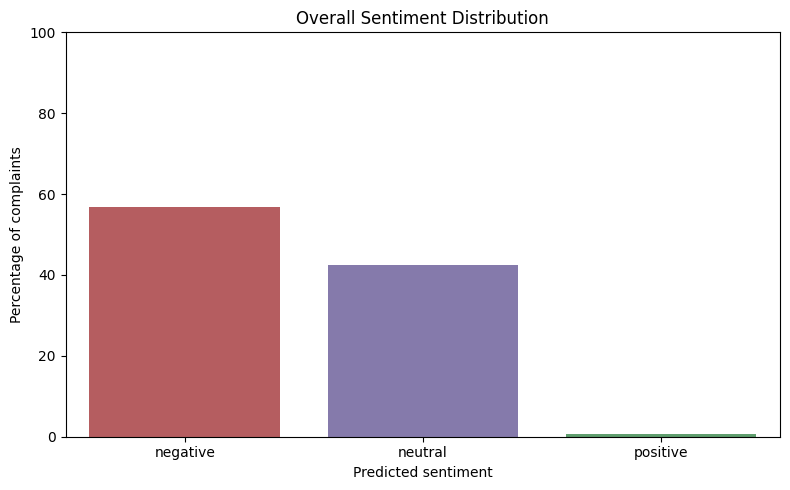

In [56]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=overall_sentiment,
    x="sentiment",
    y="percentage",
    order=SENTIMENT_LABELS,
    palette={
        "negative": "#C44E52",
        "neutral": "#8172B3",
        "positive": "#55A868"
    }
)

plt.title("Overall Sentiment Distribution")
plt.xlabel("Predicted sentiment")
plt.ylabel("Percentage of complaints")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 13. Product-Level Sentiment Analysis

Two product-level views are created:

1. **Real sentiment volumes**

   The full dataset is used to show the actual number of negative, neutral and positive complaints recorded for each product.

2. **Fair product comparison**

   The equal-product corpus is used to compare sentiment percentages across products. Because every product contributes the same number of complaints, differences are not driven by unequal product volumes.

In [57]:
real_product_summary = (
    final_output
    .groupby(
        [PRODUCT_COL, "sentiment_label"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=SENTIMENT_LABELS,
        fill_value=0
    )
)

real_product_summary["total_complaints"] = (
    real_product_summary.sum(axis=1)
)

real_product_summary["negative_percentage"] = (
    real_product_summary["negative"]
    / real_product_summary["total_complaints"]
    * 100
).round(2)

real_product_summary = (
    real_product_summary
    .sort_values(
        "total_complaints",
        ascending=False
    )
    .reset_index()
)

display(real_product_summary)

sentiment_label,product,negative,neutral,positive,total_complaints,negative_percentage
0,Debt collection,41841,56772,1997,100610,41.59
1,"Money transfer, virtual currency, or money ser...",52775,12083,4,64862,81.37
2,Checking or savings account,29867,21564,17,51448,58.05
3,Credit card,22656,18823,38,41517,54.57
4,Mortgage,7314,6694,21,14029,52.13


In [58]:
prediction_columns = [
    ID_COL,
    "sentiment_label",
    "negative_probability",
    "neutral_probability",
    "positive_probability",
    "sentiment_confidence",
    "sentiment_chunk_count"
]

equal_product_sentiment = (
    equal_product_ids
    .merge(
        final_output[prediction_columns],
        on=ID_COL,
        how="left",
        validate="one_to_one"
    )
)

print(
    "Equal-product sentiment dataset:",
    equal_product_sentiment.shape
)

print(
    "Missing sentiment labels:",
    equal_product_sentiment["sentiment_label"]
    .isna()
    .sum()
)

Equal-product sentiment dataset: (52975, 8)
Missing sentiment labels: 0


In [59]:
equal_product_summary = (
    equal_product_sentiment
    .groupby(
        [PRODUCT_COL, "sentiment_label"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=SENTIMENT_LABELS,
        fill_value=0
    )
)

equal_product_summary["total_complaints"] = (
    equal_product_summary.sum(axis=1)
)

for sentiment in SENTIMENT_LABELS:
    equal_product_summary[
        f"{sentiment}_percentage"
    ] = (
        equal_product_summary[sentiment]
        / equal_product_summary["total_complaints"]
        * 100
    ).round(2)

equal_product_summary = (
    equal_product_summary
    .sort_values(
        "negative_percentage",
        ascending=False
    )
    .reset_index()
)

display(equal_product_summary)

sentiment_label,product,negative,neutral,positive,total_complaints,negative_percentage,neutral_percentage,positive_percentage
0,"Money transfer, virtual currency, or money ser...",8607,1987,1,10595,81.24,18.75,0.01
1,Checking or savings account,6147,4444,4,10595,58.02,41.94,0.04
2,Credit card,5728,4856,11,10595,54.06,45.83,0.10
3,Mortgage,5521,5055,19,10595,52.11,47.71,0.18
4,Debt collection,4442,5954,199,10595,41.93,56.20,1.88


### Product-Level Interpretation

The full dataset shows both the actual number of complaints and the sentiment distribution within each product. Debt collection has the largest complaint volume, with 100,610 records. However, complaint volume alone does not indicate the highest concentration of negative sentiment.

The equal-product corpus provides a fairer comparison because every product contains exactly 10,595 complaints. In this balanced dataset:

- Money transfer, virtual currency, or money service has the highest negative sentiment percentage at 81.24%.
- Checking or savings accounts follow at 58.02%.
- Credit cards record 54.06%.
- Mortgages record 52.11%.
- Debt collection has the lowest negative percentage at 41.93%, with most complaints classified as neutral.

The rankings are almost identical in the full and balanced datasets. This suggests that the observed product differences are not simply caused by unequal complaint volumes.

The unusually high proportion of neutral and positive classifications for debt collection should be interpreted cautiously. Some debt-collection narratives use formal, factual, or template-based language that FinBERT may classify as neutral even though the underlying complaint describes an adverse situation. The positive category is also very small for most products and should not be interpreted as customer satisfaction without human-labelled validation.

These findings are exploratory model outputs, not measured sentiment accuracy.

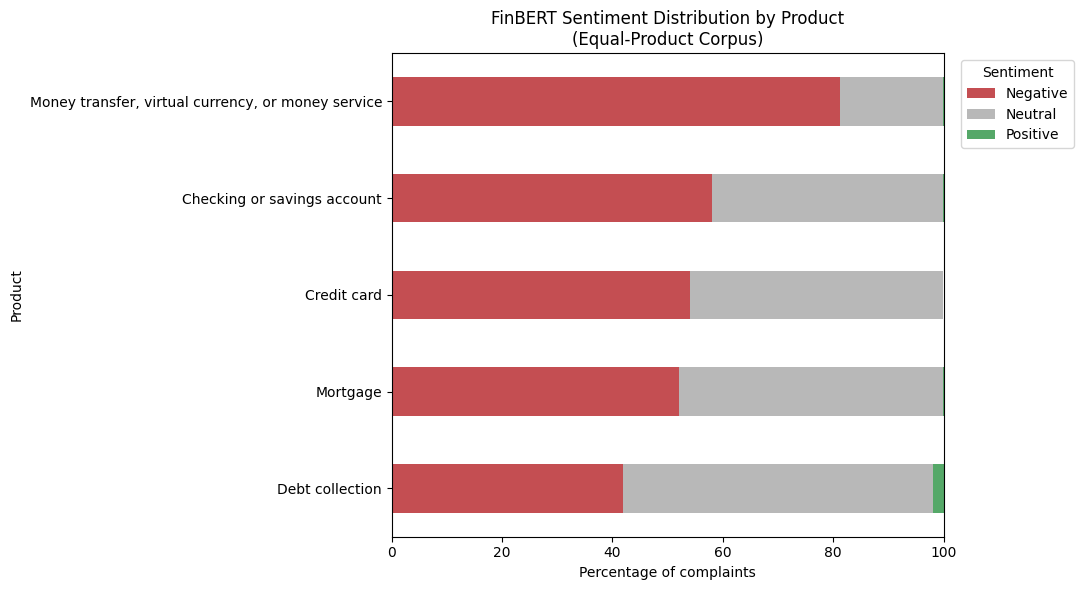

In [60]:
import matplotlib.pyplot as plt

plot_data = (
    equal_product_summary
    .set_index(PRODUCT_COL)[
        [
            "negative_percentage",
            "neutral_percentage",
            "positive_percentage"
        ]
    ]
    .sort_values("negative_percentage", ascending=True)
)

ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=["#C44E52", "#B8B8B8", "#55A868"]
)

ax.set_title(
    "FinBERT Sentiment Distribution by Product\n"
    "(Equal-Product Corpus)"
)
ax.set_xlabel("Percentage of complaints")
ax.set_ylabel("Product")
ax.legend(
    ["Negative", "Neutral", "Positive"],
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xlim(0, 100)
plt.tight_layout()
plt.show()